In [32]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import svm


In [33]:
# Load dataset
df = pd.read_csv('/content/Esha-Dataset.csv')

df.head()



,text,label
0,This video is especially focused on Pakistan&#...,non-abusive
1,Bhaiya Shree RAJNEESH OSHO ke upar yek video j...,non-abusive
2,For how much did you sold your brain and heart...,non-abusive
3,You are doing great job sir<br>I&#39;m from Ma...,non-abusive
4,Pakistan ne bharat par hi hamla shuru kr diya...,non-abusive


In [45]:
df['label'] = df['label'].str.lower().map({'abusive': 'A', 'non-abusive': 'NA'})

In [46]:
df.head()

,text,label,cleaned_text
0,This video is especially focused on Pakistan&#...,NA,this video is especially focused on pakistans ...
1,Bhaiya Shree RAJNEESH OSHO ke upar yek video j...,NA,bhaiya shree rajneesh osho upar yek video jaru...
2,For how much did you sold your brain and heart...,NA,for how much did you sold your brain and heart...
3,You are doing great job sir<br>I&#39;m from Ma...,NA,you are doing great job sirbrim from maharasht...
4,Pakistan ne bharat par hi hamla shuru kr diya...,NA,pakistan bharat hamla shuru kr diya


In [47]:
df.shape

(5802, 3)

In [48]:
print(df['label'].value_counts())

label
NA    4279
A     1523
Name: count, dtype: int64


In [49]:
# Step 1: Handle Missing Values
total_missing = df['text'].isnull().sum()
total_missing

np.int64(0)

In [50]:
df.dropna(subset=['text'], inplace=True)

In [51]:
total_duplicates = df.duplicated(subset=['text']).sum()
total_duplicates

np.int64(0)

In [52]:
df.drop_duplicates(subset=['text'], inplace=True)

In [53]:
def normalize_roman_urdu(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_text'] = df['text'].apply(normalize_roman_urdu)

In [54]:
df['cleaned_text']

,cleaned_text
0,this video is especially focused on pakistans ...
1,bhaiya shree rajneesh osho ke upar yek video j...
2,for how much did you sold your brain and heart...
3,you are doing great job sirbrim from maharasht...
4,pakistan ne bharat par hi hamla shuru kr diya
...,...
6004,bs kroone sided analysinglooser ayse he bhonkt...
6005,bwhy use local sources to prove your utter bul...
6006,is beghairat ko main rational mind smjhta tha ...
6007,hamaray jo chotay chotay bacchay saal aur saal...


In [55]:
# Step 4: Remove Stop Words
roman_urdu_stop_words = [
    'hai','aur','ko','mein','se','ne','ki','ka','ke','liye','ho','tha','thi','the',
    'hum','apne','apni','un','wo','ye','ya','kyun','to','hi','bhi','nahi','nahin',
    'agar','magar','kya','tu','tum','mera','meri','tera','teri','hamara','hamari',
    'kuch','ab','phir','lekin','jo','jis','jise','jisko','jinki','jinke','jinko','aisa','aise',
    'aisi','waisa','waise','waisi','kyon','par','q','k','h','haan','na','nhi',
    'n','he','hoga','hogi','hain','toh',
    'hogaa','hogii'
]

def remove_stop_words(text):
    words = text.split()
    filtered_words = [word for word in words if word not in roman_urdu_stop_words]
    return ' '.join(filtered_words)

df['cleaned_text'] = df['cleaned_text'].apply(remove_stop_words)

In [56]:
df.shape

(5802, 3)

In [57]:
df = df[df['cleaned_text'].str.len() >= 5]
df.shape

(5802, 3)

In [60]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 3)  # Uni, Bi, Tri-grams
)

X = tfidf_vectorizer.fit_transform(df['cleaned_text'])
y = df['label']  # Labels (A/NA)

X.shape, y.shape

((5802, 5000), (5802,))

In [61]:
print("Sample Feature Names:", tfidf_vectorizer.get_feature_names_out()[:10])

Sample Feature Names: ['aa' 'aadmi' 'aaj' 'aaj tak' 'aakhir' 'aam' 'aam awam' 'aapane' 'aapka'
 'aapke']


In [67]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.45,
    random_state=42,
    stratify=y
)

In [68]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3191, 5000), (2611, 5000), (3191,), (2611,))

In [69]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM (Linear Kernel)': svm.SVC(kernel='linear', random_state=42)
}

for name, model in models.items():
    print(f"\n--- Training {name} ---")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.2f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))



--- Training Multinomial Naive Bayes ---
Multinomial Naive Bayes Accuracy: 0.76

Classification Report:
              precision    recall  f1-score   support

           A       0.76      0.10      0.18       685
          NA       0.76      0.99      0.86      1926

    accuracy                           0.76      2611
   macro avg       0.76      0.54      0.52      2611
weighted avg       0.76      0.76      0.68      2611


--- Training Random Forest ---
Random Forest Accuracy: 0.77

Classification Report:
              precision    recall  f1-score   support

           A       0.67      0.24      0.35       685
          NA       0.78      0.96      0.86      1926

    accuracy                           0.77      2611
   macro avg       0.73      0.60      0.61      2611
weighted avg       0.75      0.77      0.73      2611


--- Training SVM (Linear Kernel) ---
SVM (Linear Kernel) Accuracy: 0.77

Classification Report:
              precision    recall  f1-score   support

    

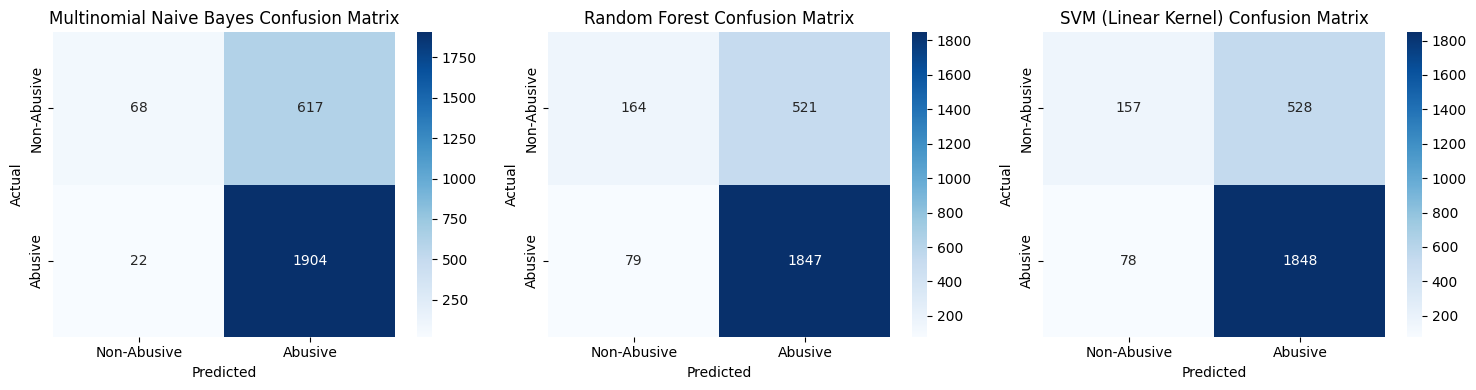

In [70]:
plt.figure(figsize=(15, 4))
for i, (name, model) in enumerate(models.items(), 1):
    plt.subplot(1, 3, i)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Non-Abusive', 'Abusive'],
                yticklabels=['Non-Abusive', 'Abusive'])
    plt.title(f'{name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

plt.tight_layout()
plt.show()



--- Model Accuracy Comparison ---
                     Model  Accuracy
1            Random Forest  0.770203
2      SVM (Linear Kernel)  0.767905
0  Multinomial Naive Bayes  0.755266


/tmp/ipython-input-3591574480.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')


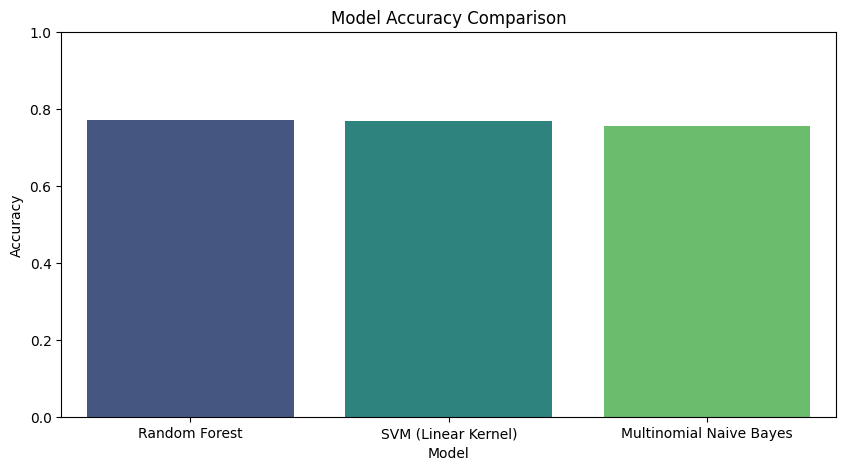

In [71]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results.append({'Model': name, 'Accuracy': accuracy})

results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print("\n--- Model Accuracy Comparison ---")
print(results_df)

plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1.0)
plt.show()


In [74]:
import joblib

# Save the TF-IDF vectorizer
joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.joblib')

# Save the trained models
for name, model in models.items():
    filename = f'{name.lower().replace(" ", "_")}_model.joblib'
    joblib.dump(model, filename)